# Laya run 3: envelope v2 — passages, neighbours, yes/no boundary (Kaggle, GPU T4 ×2)

Third run, on the new **`laya_v2`** dataset. Same labels, same lectures, same train / val / test split as runs 1 and 2.
What changes is **what Laya reads** (envelope v2, built by the app's own code, see `docs/laya-finetune/envelope-v2.md`):

* **Fixes in every v2 model:** the lecture fields come *before* the corpus text (a long hadith used to push the span out of
  the input), the duplicate verse text is gone, inputs go up to **2048 tokens** (nothing is silently cut), and the boundary is
  **two yes/no questions** — *was the start cut off?*, *was the end cut off?* — with the word-overlap evidence in the state.
  A "yes" weighs `NOUL_TRUE_WEIGHT` × in the loss (they are ~10 % of the answers).
* **The ablation**: what each new piece adds, everything else equal.

| run | consecutive verses as one passage (D) | nearest findings listed (A) | counterfactual boundary rows |
|---|---|---|---|
| `base` | – | – | – |
| `passages` | ✓ | – | – |
| `neighbours` | – | ✓ | – |
| `both` | ✓ | ✓ | – |
| `both_synth` | ✓ | ✓ | ✓ (train only) |

The **"before" line** is your current app model (`ZenoAbderrahim/laya-wahy-soft_asis`) on the v1 test file. Every model is
scored **per verse** (a passage's answer goes to each of its verses), so all lines are on exactly the same cards.

### What to read in the results
1. **Short verses** (`by context` table): *short (1-3 words) with a same-surah verse around* — the الواقعة 89 / عبس 35-36
   failure. The "real rejected" count there should drop to ~0 with D / A.
2. **No new false acceptances**: *not-a-quote recall* on your cards must not fall (A's risk: "has a neighbour → accept").
3. **Boundary**: balanced accuracy of *start cut off* / *end cut off*, against the no-model rule (0.51 on your cards).

### Kaggle settings (right-hand panel)
* **Accelerator:** `GPU T4 x2` · **Internet:** `On` · **Secrets:** `HF_TOKEN` (reads your private app model for the
  "before" line, and pushes the new models if `PUSH_TO_HUB`)
* **Input:** the **`laya_v2`** dataset (upload `data/laya_datagen/laya_v2.zip` as a new dataset, see the guide)
* **Run:** *Save Version → Save & Run All (Commit)*, browser can be closed. Expect **~3–3.5 h** (5 trainings at 2 epochs).
  `both` runs first, so a session that dies late still has the main answer.
* **Download afterwards:** only the `results/` folder of the version's Output (a few MB). Put it in
  `data/laya_datagen/results/run3/` and open `notebooks/results/laya_v2_compare.ipynb`.

## 1. Environment & dual T4 GPU check

In [1]:
!nvidia-smi
import os, subprocess, torch

n_gpu = torch.cuda.device_count()
print(f"CUDA Available: {torch.cuda.is_available()} | Visible GPUs: {n_gpu}")
for i in range(n_gpu):
    p = torch.cuda.get_device_properties(i)
    print(f"  GPU {i}: {p.name} ({p.total_memory / 1e9:.1f} GB)")

assert n_gpu >= 2, (
    f"Expected 2 GPUs, but detected {n_gpu}! Notebook options -> Accelerator -> GPU T4 x2."
)
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

Tue Oct 27 06:23:36 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Install dependencies

In [2]:
# pinned to the 0.4 line the Wahy data was validated with (laya.train / laya.calibrate are identical 0.4.12 -> 0.4.15)
!pip install -q -U "laya>=0.4.12,<0.5" "transformers>=4.48.0" safetensors huggingface_hub pandas matplotlib tabulate
import laya, transformers
print("Laya version        :", laya.__version__)
print("Transformers version:", transformers.__version__)
print("PyTorch version     :", torch.__version__)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
ydata-profiling 4.18.4 requires matplotlib<=3.10,>=3.5, but you have matplotlib 3.11.2 which is incompatible.
ydata-profiling 4.18.4 requires pandas!=1.4.0,<3.0,>1.5, but you have pandas 3.1.0 which is incompatible.
google-colab 1.0.0 requires jupyter-server==2.20.0, but you have jupyter-server 2.12.5 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
cudf-cu12 26.2.1 requires pandas<2

## 3. Dataset, scripts, base checkpoint, Hub login
Stops early if the input is not `laya_v2` (envelope 2) or its scripts are older than this notebook.

In [3]:
import glob, json, sys
from pathlib import Path
from huggingface_hub import snapshot_download, login
from laya.agent import _fix_tokenizer_config

DATA = next(Path(p).parent for p in sorted(glob.glob("/kaggle/input/**/manifest.json", recursive=True))
            if json.loads(Path(p).read_text()).get("name") == "laya_v2")
manifest = json.loads((DATA / "manifest.json").read_text())
assert manifest["envelope"] == 2, "not an envelope-v2 dataset"
assert "--noul-true-weight" in (DATA / "train_ddp.py").read_text() and "def per_verse" in (DATA / "eval_laya.py").read_text(), (
    "Old scripts in the dataset: rebuild laya_v2.zip and upload it as a NEW VERSION of the dataset, then re-run.")
sys.path.insert(0, str(DATA))
import eval_laya

print("dataset:", DATA, "| created", manifest["created"], "| base model", manifest["base_model"],
      "| max_len", manifest["max_len"], "| variants", list(manifest["variants"]))
MODEL_ID = manifest["base_model"]          # convaiinnovations/laya-multilingual
model_dir = snapshot_download(MODEL_ID)
_fix_tokenizer_config(model_dir)
print("base checkpoint:", model_dir)

try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
    login(token=HF_TOKEN)
    print("Hub: logged in")
except Exception as e:
    HF_TOKEN = None
    print("Hub: no HF_TOKEN secret, the 'before' line (private model) and the push will be skipped:", e)

dataset: /kaggle/input/datasets/abderrahimzineddine/laya-v2/laya_v2 | created 2026-10-27 | base model convaiinnovations/laya-multilingual | max_len 2048 | variants ['base', 'passages', 'neighbours', 'both', 'both_synth']


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

base checkpoint: /root/.cache/huggingface/hub/models--convaiinnovations--laya-multilingual/snapshots/1720e3e3357cfe1e281542e223f8273b0890ca34
Hub: logged in


## 4. Settings
Everything not listed here is run 2's recipe (effective batch 64, RLCD, the same learning rates, 2 epochs). The micro-batch
is 4 × 8 accumulation steps instead of 8 × 4 (same effective batch) because inputs can now be 2048 tokens long.

In [4]:
RUNS = ["both", "base", "passages", "neighbours", "both_synth"]       # order: the main answer first
NOUL_TRUE_WEIGHT = 3.0      # a "yes, cut off" answer weighs 3x in the loss (~10 % of the yes/no answers are yes)
TRAIN_ARGS = (f"--epochs 2 --micro-batch 4 --grad-accum 8 --lr-encoder 2.5e-5 --lr-head 1e-4 --loss rlcd "
              f"--max-len {manifest['max_len']} --head-max-len {manifest['head_max_len']} --noul-true-weight {NOUL_TRUE_WEIGHT}")
APP_FALSE_SHARE = 0.10      # the app's real stream is ~10 % "not a quote" (prior-corrected numbers)
BEFORE_MODEL = "ZenoAbderrahim/laya-wahy-soft_asis"     # the app's current model: the "before" line (v1 envelope)
PUSH_TO_HUB = True          # upload every new model to a PRIVATE Hub repo (needs the HF_TOKEN secret)
HUB_PREFIX = "ZenoAbderrahim/laya-wahy-v2"              # repo = f"{HUB_PREFIX}-{run}"

WORK = Path("/kaggle/working")
for d in ("results", "logs"):
    (WORK / d).mkdir(parents=True, exist_ok=True)

def run(cmd, log):
    # Run a shell command, stream its output here and into a log file; returns the exit code.
    print("$", cmd, flush=True)
    with open(log, "w") as f:
        p = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
        for line in p.stdout:
            f.write(line)
            if "Warning" not in line and "warn(" not in line:
                print(line, end="", flush=True)
        return p.wait()

import pandas as pd
train_false_share = {}
rows = []
for name in RUNS:
    v = manifest["variants"][name]
    tr = v["train"]
    train_false_share[name] = round(tr.get("verdict FALSE", 0) / tr["rows"], 4)
    rows.append({"run": name, "about": v["about"], "train rows": tr["rows"], "passages": tr.get("passages", 0),
                 "synthetic": tr.get("synthetic", 0), "start yes / items": f"{tr.get('start_missing true', 0)} / {tr.get('start_missing items', 0)}",
                 "end yes / items": f"{tr.get('end_missing true', 0)} / {tr.get('end_missing items', 0)}",
                 "val rows": v["val"]["rows"], "test rows": v["test"]["rows"], "test verses": v["test"]["verses (labelled)"]})
pd.DataFrame(rows).set_index("run")

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


,about,train rows,passages,synthetic,start yes / items,end yes / items,val rows,test rows,test verses
run,,,,,,,,,
both,+ D + A,2728,105,0,157 / 1299,125 / 1298,496,1470,1523
base,"envelope v2 alone (field order, no duplicate v...",2863,0,0,169 / 1443,132 / 1443,515,1523,1523
passages,+ consecutive verses as one row (D),2728,105,0,157 / 1299,125 / 1298,496,1470,1523
neighbours,"+ nearest other findings, no verdicts (A)",2863,0,0,169 / 1443,132 / 1443,515,1523,1523
both_synth,D + A + counterfactual 'cut off' boundary rows...,3428,151,700,517 / 1995,466 / 1994,496,1470,1523


## 5. The "before" line: your current app model on the v1 test file
Same cards, one row per verse, the v1 envelope it was trained on. Also scores the cached JEV / Gemini / base-Laya answers
and the shortcut baselines once (`baseline_*.json`).

In [5]:
flags = f"--verse-flags {DATA}/test_verse_flags.json"
if HF_TOKEN:
    rc = run(f"python {DATA}/eval_laya.py predict --model {BEFORE_MODEL} --name 'before: soft_asis (app)' "
             f"--test {DATA}/v1_test.jsonl --out {WORK}/results/before_soft_asis.json --app-false-share {APP_FALSE_SHARE} "
             f"--batch-size 32 --baselines {DATA}/v1_baselines.json {flags}", WORK / "logs" / "eval_before.log")
    print("before:", "ok" if rc == 0 else f"failed (exit {rc}), see logs/eval_before.log")

$ python /kaggle/input/datasets/abderrahimzineddine/laya-v2/laya_v2/eval_laya.py predict --model ZenoAbderrahim/laya-wahy-soft_asis --name 'before: soft_asis (app)' --test /kaggle/input/datasets/abderrahimzineddine/laya-v2/laya_v2/v1_test.jsonl --out /kaggle/working/results/before_soft_asis.json --app-false-share 0.1 --batch-size 32 --baselines /kaggle/input/datasets/abderrahimzineddine/laya-v2/laya_v2/v1_baselines.json --verse-flags /kaggle/input/datasets/abderrahimzineddine/laya-v2/laya_v2/test_verse_flags.json

Fetching 5 files: 100%|██████████| 5/5 [00:10<00:00,  2.18s/it]
  640/1523 rows, 41s
  1280/1523 rows, 83s
| model | cards | verdict accuracy | not-a-quote recall | not-a-quote precision | real wrongly rejected | AUC | ECE | boundary accuracy |
|---|---|---|---|---|---|---|---|---|
| before: soft_asis (app) | 198 | 91.4 % [87–95] | 77.8 % [59–89] | 65.6 % [48–80] | 6.4 % [4–11] | 0.944 | 0.084 | 44.8 % [37–53] |
before: ok


## 6. Train + evaluate
Per run: `torchrun` trains on both GPUs (the checkpoint's config records `wahy_envelope: 2` and the run's options, so the
app knows what to send it), then `eval_laya.py` scores it on that variant's test file, per verse. The val line after each
epoch prints the yes/no boundary's **balanced** accuracy: it should climb well above 0.5.

In [6]:
import time
status = {}
for name in RUNS:
    v = manifest["variants"][name]
    out = WORK / "models" / name
    t0 = time.time()
    try:
        cfg_extra = json.dumps(v["cfg_extra"]).replace('"', '\\"')
        rc = run(f"torchrun --standalone --nproc_per_node=2 {DATA}/train_ddp.py {model_dir} {out} "
                 f"--train {DATA}/{name}/train.jsonl --val {DATA}/{name}/val.jsonl --name laya-wahy-v2-{name} "
                 f"--cfg-extra \"{cfg_extra}\" {TRAIN_ARGS}", WORK / "logs" / f"train_{name}.log")
        if rc != 0 or not (out / "model.safetensors").exists():
            status[name] = f"training failed (exit {rc}), see logs/train_{name}.log"
            continue
        rc = run(f"python {DATA}/eval_laya.py predict --model {out} --name {name} --test {DATA}/{name}/test.jsonl "
                 f"--out {WORK}/results/{name}.json --train-false-share {train_false_share[name]} "
                 f"--app-false-share {APP_FALSE_SHARE} --batch-size 16 {flags}", WORK / "logs" / f"eval_{name}.log")
        status[name] = f"ok in {(time.time() - t0) / 60:.0f} min" if rc == 0 else f"evaluation failed (exit {rc})"
        train_log = out / "train_log.json"
        if train_log.exists():
            (WORK / "results" / f"train_log_{name}.json").write_text(train_log.read_text())
    except Exception as e:
        status[name] = f"error: {e}"
    print(f"\n##### {name}: {status[name]}\n", flush=True)
json.dump(status, open(WORK / "results" / "status.json", "w"), indent=1)
status

$ torchrun --standalone --nproc_per_node=2 /kaggle/input/datasets/abderrahimzineddine/laya-v2/laya_v2/train_ddp.py /root/.cache/huggingface/hub/models--convaiinnovations--laya-multilingual/snapshots/1720e3e3357cfe1e281542e223f8273b0890ca34 /kaggle/working/models/both --train /kaggle/input/datasets/abderrahimzineddine/laya-v2/laya_v2/both/train.jsonl --val /kaggle/input/datasets/abderrahimzineddine/laya-v2/laya_v2/both/val.jsonl --name laya-wahy-v2-both --cfg-extra "{\"wahy_envelope\": 2, \"wahy_envelope_options\": {\"passages\": true, \"neighbours\": true}}" --epochs 2 --micro-batch 4 --grad-accum 8 --lr-encoder 2.5e-5 --lr-head 1e-4 --loss rlcd --max-len 2048 --head-max-len 256 --noul-true-weight 3.0
W1027 06:26:48.057000 151 torch/distributed/run.py:851] 
W1027 06:26:48.057000 151 torch/distributed/run.py:851] *****************************************
W1027 06:26:48.057000 151 torch/distributed/run.py:851] Setting OMP_NUM_THREADS environment variable for each process to be 1 in defau

{'both': 'ok in 32 min',
 'base': 'ok in 27 min',
 'passages': 'ok in 26 min',
 'neighbours': 'ok in 34 min',
 'both_synth': 'ok in 39 min'}

## 7. Load the results (+ the no-model boundary rule)

In [7]:
from IPython.display import Markdown, display
v1_rows = eval_laya.read_jsonl(DATA / "v1_test.jsonl")
vflags = json.loads((DATA / "test_verse_flags.json").read_text())
res = {n: json.load(open(WORK / "results" / f"{n}.json")) for n in RUNS if (WORK / "results" / f"{n}.json").exists()}
before = [json.load(open(WORK / "results" / "before_soft_asis.json"))] if (WORK / "results" / "before_soft_asis.json").exists() else []
rule = eval_laya.evaluate(*eval_laya.per_verse(v1_rows, eval_laya.rule_predictions(v1_rows), vflags), "word-overlap rule (no model)")
json.dump(rule, open(WORK / "results" / "rule_boundary.json", "w"), ensure_ascii=False)
teachers = [json.load(open(f)) for f in sorted(glob.glob(str(WORK / "results" / "baseline_*.json")))]
models = before + [res[n] for n in RUNS if n in res]
print("models:", [m["name"] for m in models], "| teacher baselines:", [t["name"] for t in teachers])

models: ['before: soft_asis (app)', 'both', 'base', 'passages', 'neighbours', 'both_synth'] | teacher baselines: ['7 shallow fields (LR)', 'Gemini (cached)', 'JEV (cached)', 'Laya (base) (cached)', 'span length only (LR)']


## 8. Verdict: overall, then the slices the new context is for
Columns as in runs 1–2. *real quotes wrongly rejected* is the costly error; *not-a-quote recall* must not fall.

In [8]:
report = []
for g in ["you", "you + Sonnet", "Sonnet · other lectures", "written text"]:
    t = f"### verdict · {g}\n" + eval_laya.compare(models + teachers, g)
    report.append(t); display(Markdown(t))
for g in ["you", "you + Sonnet"]:
    for part in ("by context", "by span length"):
        t = f"### verdict {part} · {g}\n" + eval_laya.compare_slices(models, g, part)
        report.append(t); display(Markdown(t))
(WORK / "results" / "comparison.md").write_text("\n\n".join(report))

### verdict · you
| model | cards | verdict accuracy | not-a-quote recall | not-a-quote precision | real wrongly rejected | AUC | ECE | boundary accuracy |
|---|---|---|---|---|---|---|---|---|
| before: soft_asis (app) | 198 | 91.4 % [87–95] | 77.8 % [59–89] | 65.6 % [48–80] | 6.4 % [4–11] | 0.944 | 0.084 | 44.8 % [37–53] |
| both | 198 | 88.4 % [83–92] | 59.3 % [41–75] | 57.1 % [39–73] | 7.0 % [4–12] | 0.890 | 0.096 | 44.8 % [37–53] |
| base | 198 | 86.9 % [81–91] | 63.0 % [44–78] | 51.5 % [35–68] | 9.4 % [6–15] | 0.888 | 0.089 | 44.8 % [37–53] |
| passages | 198 | 82.8 % [77–87] | 70.4 % [52–84] | 42.2 % [29–57] | 15.2 % [11–21] | 0.891 | 0.064 | 44.8 % [37–53] |
| neighbours | 198 | 85.9 % [80–90] | 63.0 % [44–78] | 48.6 % [33–64] | 10.5 % [7–16] | 0.870 | 0.061 | 44.8 % [37–53] |
| both_synth | 198 | 84.3 % [79–89] | 48.1 % [31–66] | 43.3 % [27–61] | 9.9 % [6–15] | 0.857 | 0.102 | 51.7 % [44–60] |
| 7 shallow fields (LR) | 198 | 83.8 % [78–88] | 66.7 % [48–81] | 43.9 % [30–59] | 13.5 % [9–19] | 0.857 | 0.040 | — |
| Gemini (cached) | 147 | 89.8 % [84–94] | 41.7 % [24–61] | 100.0 % [72–100] | 0.0 % [0–3] | 0.708 | 0.102 | 50.0 % [40–60] |
| JEV (cached) | 147 | 86.4 % [80–91] | 20.8 % [9–40] | 100.0 % [57–100] | 0.0 % [0–3] | 0.604 | 0.136 | 52.9 % [43–62] |
| Laya (base) (cached) | 111 | 54.0 % [45–63] | 88.9 % [56–98] | 14.0 % [7–25] | 48.0 % [39–58] | 0.704 | 0.460 | 30.4 % [22–40] |
| span length only (LR) | 198 | 79.3 % [73–84] | 29.6 % [16–48] | 26.7 % [14–44] | 12.9 % [9–19] | 0.723 | 0.109 | — |

### verdict · you + Sonnet
| model | cards | verdict accuracy | not-a-quote recall | not-a-quote precision | real wrongly rejected | AUC | ECE | boundary accuracy |
|---|---|---|---|---|---|---|---|---|
| before: soft_asis (app) | 1243 | 90.9 % [89–92] | 92.4 % [90–94] | 88.6 % [86–91] | 10.4 % [8–13] | 0.960 | 0.082 | 70.8 % [67–74] |
| both | 1243 | 87.8 % [86–90] | 88.3 % [85–91] | 86.1 % [83–89] | 12.5 % [10–15] | 0.953 | 0.099 | 70.8 % [67–74] |
| base | 1243 | 87.9 % [86–90] | 87.1 % [84–90] | 87.1 % [84–90] | 11.3 % [9–14] | 0.947 | 0.088 | 70.8 % [67–74] |
| passages | 1243 | 87.4 % [85–89] | 91.4 % [89–93] | 83.2 % [80–86] | 16.2 % [14–19] | 0.944 | 0.074 | 71.0 % [67–74] |
| neighbours | 1243 | 88.5 % [87–90] | 89.5 % [87–92] | 86.4 % [83–89] | 12.4 % [10–15] | 0.947 | 0.084 | 70.8 % [67–74] |
| both_synth | 1243 | 87.1 % [85–89] | 87.1 % [84–90] | 85.6 % [83–88] | 12.8 % [10–16] | 0.949 | 0.080 | 67.7 % [64–71] |
| 7 shallow fields (LR) | 1243 | 85.5 % [83–87] | 89.3 % [87–92] | 81.5 % [78–84] | 17.8 % [15–21] | 0.932 | 0.035 | — |
| Gemini (cached) | 180 | 90.0 % [85–94] | 38.5 % [22–57] | 90.9 % [62–98] | 0.7 % [0–4] | 0.689 | 0.100 | 51.9 % [43–60] |
| JEV (cached) | 180 | 87.2 % [82–91] | 19.2 % [9–38] | 83.3 % [44–97] | 0.7 % [0–4] | 0.593 | 0.128 | 54.9 % [46–63] |
| Laya (base) (cached) | 111 | 54.0 % [45–63] | 88.9 % [56–98] | 14.0 % [7–25] | 48.0 % [39–58] | 0.704 | 0.460 | 30.4 % [22–40] |
| span length only (LR) | 1243 | 81.7 % [79–84] | 78.7 % [75–82] | 81.5 % [78–84] | 15.7 % [13–19] | 0.890 | 0.042 | — |

### verdict · Sonnet · other lectures
| model | cards | verdict accuracy | not-a-quote recall | not-a-quote precision | real wrongly rejected | AUC | ECE | boundary accuracy |
|---|---|---|---|---|---|---|---|---|
| before: soft_asis (app) | 596 | 90.9 % [88–93] | 91.4 % [87–94] | 88.7 % [84–92] | 9.4 % [7–13] | 0.957 | 0.074 | 82.4 % [78–86] |
| both | 596 | 88.4 % [86–91] | 89.1 % [85–92] | 85.6 % [81–89] | 12.2 % [9–16] | 0.958 | 0.102 | 82.4 % [78–86] |
| base | 596 | 88.6 % [86–91] | 87.3 % [83–91] | 87.3 % [83–91] | 10.3 % [7–14] | 0.951 | 0.097 | 82.4 % [78–86] |
| passages | 596 | 88.9 % [86–91] | 93.3 % [90–96] | 83.8 % [79–88] | 14.6 % [11–19] | 0.950 | 0.088 | 82.7 % [78–86] |
| neighbours | 596 | 88.9 % [86–91] | 89.5 % [85–93] | 86.3 % [82–90] | 11.6 % [9–15] | 0.956 | 0.094 | 82.4 % [78–86] |
| both_synth | 596 | 88.1 % [85–90] | 88.4 % [84–92] | 85.5 % [81–89] | 12.2 % [9–16] | 0.954 | 0.083 | 73.2 % [68–78] |
| 7 shallow fields (LR) | 596 | 86.6 % [84–89] | 91.8 % [88–94] | 80.9 % [76–85] | 17.6 % [14–22] | 0.941 | 0.057 | — |
| span length only (LR) | 596 | 81.9 % [79–85] | 80.9 % [76–85] | 79.1 % [74–84] | 17.3 % [14–22] | 0.897 | 0.051 | — |

### verdict · written text
| model | cards | verdict accuracy | not-a-quote recall | not-a-quote precision | real wrongly rejected | AUC | ECE | boundary accuracy |
|---|---|---|---|---|---|---|---|---|
| before: soft_asis (app) | 280 | 90.4 % [86–93] | 83.3 % [44–97] | 16.1 % [7–33] | 9.5 % [7–14] | 0.843 | 0.073 | 62.4 % [56–68] |
| both | 280 | 88.9 % [85–92] | 83.3 % [44–97] | 14.3 % [6–29] | 10.9 % [8–15] | 0.821 | 0.116 | 62.4 % [56–68] |
| base | 280 | 89.6 % [86–93] | 83.3 % [44–97] | 15.2 % [7–31] | 10.2 % [7–14] | 0.798 | 0.109 | 62.4 % [56–68] |
| passages | 280 | 88.9 % [85–92] | 83.3 % [44–97] | 14.3 % [6–29] | 10.9 % [8–15] | 0.864 | 0.089 | 63.1 % [57–69] |
| neighbours | 280 | 87.9 % [84–91] | 66.7 % [30–90] | 11.1 % [4–25] | 11.7 % [8–16] | 0.822 | 0.085 | 62.4 % [56–68] |
| both_synth | 280 | 89.6 % [86–93] | 83.3 % [44–97] | 15.2 % [7–31] | 10.2 % [7–14] | 0.823 | 0.089 | 60.5 % [55–66] |
| 7 shallow fields (LR) | 280 | 92.9 % [89–95] | 83.3 % [44–97] | 20.8 % [9–40] | 6.9 % [4–11] | 0.904 | 0.051 | — |
| span length only (LR) | 280 | 82.9 % [78–87] | 83.3 % [44–97] | 9.6 % [4–21] | 17.2 % [13–22] | 0.919 | 0.169 | — |

### verdict by context · you
| model | inside a passage of consecutive verses (acc · real rejected) | next to a verse of the same surah (<= 3 ayat away) (acc · real rejected) | short (1-3 words) and isolated (acc · real rejected) | short (1-3 words) with a same-surah verse around (acc · real rejected) | has any neighbour finding (<= 40 words) (acc · real rejected) | no neighbour finding (acc · real rejected) |
|---|---|---|---|---|---|---|
| before: soft_asis (app) | 100.0 % [76–100] · 0/12 | 81.8 % [52–95] · 2/11 | 69.2 % [42–87] · 3/7 | 100.0 % [51–100] · 0/4 | 93.3 % [88–96] · 5/120 | 87.3 % [77–93] · 6/51 |
| both | 100.0 % [76–100] · 0/12 | 90.9 % [62–98] · 1/11 | 76.9 % [50–92] · 3/7 | 100.0 % [51–100] · 0/4 | 92.6 % [87–96] · 6/120 | 79.4 % [68–88] · 6/51 |
| base | 100.0 % [76–100] · 0/12 | 81.8 % [52–95] · 2/11 | 69.2 % [42–87] · 3/7 | 100.0 % [51–100] · 0/4 | 91.8 % [86–95] · 6/120 | 76.2 % [64–85] · 10/51 |
| passages | 100.0 % [76–100] · 0/12 | 72.7 % [43–90] · 3/11 | 53.8 % [29–77] · 5/7 | 75.0 % [30–95] · 1/4 | 88.9 % [82–93] · 12/120 | 69.8 % [58–80] · 14/51 |
| neighbours | 100.0 % [76–100] · 0/12 | 72.7 % [43–90] · 3/11 | 69.2 % [42–87] · 3/7 | 100.0 % [51–100] · 0/4 | 88.9 % [82–93] · 11/120 | 79.4 % [68–88] · 7/51 |
| both_synth | 100.0 % [76–100] · 0/12 | 81.8 % [52–95] · 2/11 | 69.2 % [42–87] · 3/7 | 100.0 % [51–100] · 0/4 | 89.6 % [83–94] · 10/120 | 73.0 % [61–82] · 7/51 |

### verdict by span length · you
| model | 1-3 words (acc · real rejected) | 4-8 words (acc · real rejected) | 9+ words (acc · real rejected) |
|---|---|---|---|
| before: soft_asis (app) | 76.5 % [53–90] · 3/11 | 85.3 % [76–92] · 7/60 | 98.1 % [93–99] · 1/100 |
| both | 82.3 % [59–94] · 3/11 | 76.0 % [65–84] · 8/60 | 98.1 % [93–99] · 1/100 |
| base | 76.5 % [53–90] · 3/11 | 76.0 % [65–84] · 12/60 | 96.2 % [91–99] · 1/100 |
| passages | 58.8 % [36–78] · 6/11 | 72.0 % [61–81] · 16/60 | 94.3 % [88–97] · 4/100 |
| neighbours | 76.5 % [53–90] · 3/11 | 72.0 % [61–81] · 15/60 | 97.2 % [92–99] · 0/100 |
| both_synth | 76.5 % [53–90] · 3/11 | 69.3 % [58–79] · 12/60 | 96.2 % [91–99] · 2/100 |

### verdict by context · you + Sonnet
| model | inside a passage of consecutive verses (acc · real rejected) | next to a verse of the same surah (<= 3 ayat away) (acc · real rejected) | short (1-3 words) and isolated (acc · real rejected) | short (1-3 words) with a same-surah verse around (acc · real rejected) | has any neighbour finding (<= 40 words) (acc · real rejected) | no neighbour finding (acc · real rejected) |
|---|---|---|---|---|---|---|
| before: soft_asis (app) | 95.3 % [87–98] · 3/64 | 79.5 % [66–89] · 7/33 | 91.9 % [89–94] · 23/39 | 82.6 % [63–93] · 3/14 | 91.0 % [89–93] · 57/510 | 90.3 % [86–93] · 12/152 |
| both | 100.0 % [94–100] · 0/64 | 86.4 % [73–94] · 4/33 | 89.8 % [86–92] · 30/39 | 87.0 % [68–95] · 2/14 | 89.0 % [87–91] · 68/510 | 82.8 % [77–87] · 15/152 |
| base | 98.4 % [92–100] · 1/64 | 86.4 % [73–94] · 5/33 | 90.9 % [88–93] · 23/39 | 91.3 % [73–98] · 1/14 | 88.6 % [86–90] · 58/510 | 85.3 % [80–89] · 17/152 |
| passages | 100.0 % [94–100] · 0/64 | 81.8 % [68–90] · 5/33 | 89.8 % [86–92] · 29/39 | 82.6 % [63–93] · 2/14 | 88.5 % [86–90] · 83/510 | 82.8 % [77–87] · 24/152 |
| neighbours | 100.0 % [94–100] · 0/64 | 84.1 % [71–92] · 5/33 | 90.9 % [88–93] · 24/39 | 87.0 % [68–95] · 1/14 | 89.5 % [87–91] · 70/510 | 84.5 % [79–89] · 12/152 |
| both_synth | 100.0 % [94–100] · 0/64 | 81.8 % [68–90] · 5/33 | 90.6 % [87–93] · 26/39 | 82.6 % [63–93] · 2/14 | 88.5 % [86–90] · 69/510 | 81.5 % [76–86] · 16/152 |

### verdict by span length · you + Sonnet
| model | 1-3 words (acc · real rejected) | 4-8 words (acc · real rejected) | 9+ words (acc · real rejected) |
|---|---|---|---|
| before: soft_asis (app) | 91.4 % [88–94] · 26/53 | 84.9 % [81–88] · 37/256 | 97.6 % [96–99] · 6/353 |
| both | 89.7 % [86–92] · 32/53 | 79.1 % [75–83] · 45/256 | 96.3 % [94–98] · 6/353 |
| base | 90.9 % [88–93] · 24/53 | 78.9 % [75–82] · 47/256 | 95.5 % [93–97] · 4/353 |
| passages | 89.5 % [86–92] · 31/53 | 79.6 % [76–83] · 64/256 | 94.4 % [92–96] · 12/353 |
| neighbours | 90.6 % [87–93] · 25/53 | 80.4 % [77–84] · 51/256 | 95.7 % [93–97] · 6/353 |
| both_synth | 90.2 % [87–93] · 28/53 | 78.0 % [74–82] · 47/256 | 94.7 % [92–97] · 10/353 |

9703

## 9. Boundary
**Balanced accuracy** is the column to read ("always complete" = 0.25 on 4 classes, 0.5 on a yes/no). The v2 models'
4-class answer is built from the two yes/no answers; *start / end: balanced / AUC* is the yes/no question itself.

In [9]:
btext = []
for g in ["you", "written text", "you + Sonnet", "Sonnet · other lectures"]:
    t = f"### boundary · {g}\n" + eval_laya.compare_boundary([rule] + teachers + models, g)
    btext.append(t); display(Markdown(t))
(WORK / "results" / "boundary.md").write_text("\n\n".join(btext))

logs = {n: json.load(open(WORK / "results" / f"train_log_{n}.json")) for n in RUNS if (WORK / "results" / f"train_log_{n}.json").exists()}
display(pd.DataFrame([{"run": n, **{f"ep{e['epoch']} {k}": e["val"][k].get("balanced_accuracy", round(e["val"][k]["accuracy"], 4))
                                    for e in logs[n]["epochs"] for k in e["val"] if k != "all"}}
                      for n in logs]).set_index("run"))

### boundary · you
| model | cards | accuracy | **balanced accuracy** | cut-off quotes caught | COMPLETE_SPAN | MISSING_START | MISSING_END | MISSING_BOTH | start: balanced / AUC | end: balanced / AUC |
|---|---|---|---|---|---|---|---|---|---|---|
| word-overlap rule (no model) | 143 | 60.8 % [53–68] | **0.506** | 64.6 % [54–74] | 85.9 % [75–92] | 39.1 % [22–59] | 47.2 % [32–63] | 30.0 % [15–52] | 0.686 / 0.686 | 0.748 / 0.748 |
| Gemini (cached) | 102 | 50.0 % [40–60] | **0.396** | 31.8 % [22–44] | 94.9 % [83–99] | 22.2 % [9–45] | 30.8 % [16–50] | 10.5 % [3–31] | 0.593 / 0.593 | 0.627 / 0.627 |
| JEV (cached) | 102 | 52.9 % [43–62] | **0.424** | 33.3 % [23–46] | 100.0 % [91–100] | 11.1 % [3–33] | 26.9 % [14–46] | 31.6 % [15–54] | 0.620 / 0.620 | 0.669 / 0.669 |
| Laya (base) (cached) | 102 | 30.4 % [22–40] | **0.293** | 60.3 % [48–71] | 43.6 % [29–59] | 0.0 % [0–18] | 0.0 % [0–13] | 73.7 % [51–88] | 0.528 / 0.528 | 0.550 / 0.550 |
| before: soft_asis (app) | 143 | 44.8 % [37–53] | **0.250** | 0.0 % [0–5] | 100.0 % [94–100] | 0.0 % [0–14] | 0.0 % [0–10] | 0.0 % [0–16] | 0.500 / 0.647 | 0.500 / 0.615 |
| both | 143 | 44.8 % [37–53] | **0.250** | 0.0 % [0–5] | 100.0 % [94–100] | 0.0 % [0–14] | 0.0 % [0–10] | 0.0 % [0–16] | 0.500 / 0.617 | 0.500 / 0.594 |
| base | 143 | 44.8 % [37–53] | **0.250** | 0.0 % [0–5] | 100.0 % [94–100] | 0.0 % [0–14] | 0.0 % [0–10] | 0.0 % [0–16] | 0.500 / 0.702 | 0.500 / 0.617 |
| passages | 143 | 44.8 % [37–53] | **0.250** | 1.3 % [0–7] | 100.0 % [94–100] | 0.0 % [0–14] | 0.0 % [0–10] | 0.0 % [0–16] | 0.495 / 0.718 | 0.500 / 0.696 |
| neighbours | 143 | 44.8 % [37–53] | **0.250** | 0.0 % [0–5] | 100.0 % [94–100] | 0.0 % [0–14] | 0.0 % [0–10] | 0.0 % [0–16] | 0.500 / 0.729 | 0.500 / 0.657 |
| both_synth | 143 | 51.7 % [44–60] | **0.375** | 26.6 % [18–37] | 89.1 % [79–95] | 26.1 % [13–46] | 25.0 % [14–41] | 10.0 % [3–30] | 0.601 / 0.747 | 0.587 / 0.743 |

### boundary · written text
| model | cards | accuracy | **balanced accuracy** | cut-off quotes caught | COMPLETE_SPAN | MISSING_START | MISSING_END | MISSING_BOTH | start: balanced / AUC | end: balanced / AUC |
|---|---|---|---|---|---|---|---|---|---|---|
| word-overlap rule (no model) | 271 | 76.4 % [71–81] | **0.673** | 77.5 % [68–84] | 84.6 % [78–89] | 60.5 % [46–74] | 69.2 % [54–81] | 55.0 % [34–74] | 0.808 / 0.808 | 0.823 / 0.823 |
| before: soft_asis (app) | 271 | 62.4 % [56–68] | **0.250** | 0.0 % [0–4] | 100.0 % [98–100] | 0.0 % [0–8] | 0.0 % [0–9] | 0.0 % [0–16] | 0.500 / 0.762 | 0.500 / 0.697 |
| both | 271 | 62.4 % [56–68] | **0.250** | 0.0 % [0–4] | 100.0 % [98–100] | 0.0 % [0–8] | 0.0 % [0–9] | 0.0 % [0–16] | 0.500 / 0.743 | 0.500 / 0.661 |
| base | 271 | 62.4 % [56–68] | **0.250** | 0.0 % [0–4] | 100.0 % [98–100] | 0.0 % [0–8] | 0.0 % [0–9] | 0.0 % [0–16] | 0.500 / 0.808 | 0.500 / 0.808 |
| passages | 271 | 63.1 % [57–69] | **0.262** | 7.8 % [4–15] | 100.0 % [98–100] | 4.7 % [1–15] | 0.0 % [0–9] | 0.0 % [0–16] | 0.543 / 0.848 | 0.500 / 0.720 |
| neighbours | 271 | 62.4 % [56–68] | **0.250** | 1.0 % [0–5] | 100.0 % [98–100] | 0.0 % [0–8] | 0.0 % [0–9] | 0.0 % [0–16] | 0.498 / 0.843 | 0.500 / 0.736 |
| both_synth | 271 | 60.5 % [55–66] | **0.416** | 49.0 % [40–59] | 76.3 % [69–82] | 44.2 % [30–59] | 35.9 % [23–52] | 10.0 % [3–30] | 0.669 / 0.844 | 0.564 / 0.763 |

### boundary · you + Sonnet
| model | cards | accuracy | **balanced accuracy** | cut-off quotes caught | COMPLETE_SPAN | MISSING_START | MISSING_END | MISSING_BOTH | start: balanced / AUC | end: balanced / AUC |
|---|---|---|---|---|---|---|---|---|---|---|
| word-overlap rule (no model) | 634 | 68.9 % [65–72] | **0.426** | 47.0 % [40–54] | 85.1 % [81–88] | 31.1 % [22–42] | 30.2 % [22–41] | 24.0 % [12–43] | 0.635 / 0.635 | 0.670 / 0.670 |
| Gemini (cached) | 133 | 51.9 % [43–60] | **0.360** | 28.2 % [19–40] | 88.7 % [78–94] | 19.1 % [8–40] | 25.8 % [14–43] | 10.5 % [3–31] | 0.579 / 0.579 | 0.600 / 0.600 |
| JEV (cached) | 133 | 54.9 % [46–63] | **0.401** | 31.0 % [21–42] | 91.9 % [82–97] | 14.3 % [5–35] | 22.6 % [11–40] | 31.6 % [15–54] | 0.600 / 0.600 | 0.642 / 0.642 |
| Laya (base) (cached) | 102 | 30.4 % [22–40] | **0.293** | 60.3 % [48–71] | 43.6 % [29–59] | 0.0 % [0–18] | 0.0 % [0–13] | 73.7 % [51–88] | 0.528 / 0.528 | 0.550 / 0.550 |
| before: soft_asis (app) | 634 | 70.8 % [67–74] | **0.250** | 0.0 % [0–2] | 100.0 % [99–100] | 0.0 % [0–5] | 0.0 % [0–4] | 0.0 % [0–13] | 0.500 / 0.644 | 0.500 / 0.610 |
| both | 634 | 70.8 % [67–74] | **0.250** | 0.0 % [0–2] | 100.0 % [99–100] | 0.0 % [0–5] | 0.0 % [0–4] | 0.0 % [0–13] | 0.500 / 0.634 | 0.500 / 0.596 |
| base | 634 | 70.8 % [67–74] | **0.250** | 0.0 % [0–2] | 100.0 % [99–100] | 0.0 % [0–5] | 0.0 % [0–4] | 0.0 % [0–13] | 0.500 / 0.645 | 0.500 / 0.638 |
| passages | 634 | 71.0 % [67–74] | **0.253** | 1.1 % [0–4] | 100.0 % [99–100] | 1.4 % [0–7] | 0.0 % [0–4] | 0.0 % [0–13] | 0.504 / 0.678 | 0.500 / 0.658 |
| neighbours | 634 | 70.8 % [67–74] | **0.250** | 0.0 % [0–2] | 100.0 % [99–100] | 0.0 % [0–5] | 0.0 % [0–4] | 0.0 % [0–13] | 0.500 / 0.657 | 0.500 / 0.610 |
| both_synth | 634 | 67.7 % [64–71] | **0.326** | 17.8 % [13–24] | 89.8 % [87–92] | 14.9 % [9–25] | 14.0 % [8–23] | 12.0 % [4–30] | 0.559 / 0.699 | 0.558 / 0.712 |

### boundary · Sonnet · other lectures
| model | cards | accuracy | **balanced accuracy** | cut-off quotes caught | COMPLETE_SPAN | MISSING_START | MISSING_END | MISSING_BOTH | start: balanced / AUC | end: balanced / AUC |
|---|---|---|---|---|---|---|---|---|---|---|
| word-overlap rule (no model) | 329 | 79.6 % [75–84] | **0.374** | 34.5 % [24–47] | 90.4 % [86–93] | 33.3 % [19–51] | 25.9 % [13–45] | 0.0 % [0–79] | 0.642 / 0.642 | 0.612 / 0.612 |
| before: soft_asis (app) | 329 | 82.4 % [78–86] | **0.250** | 0.0 % [0–6] | 100.0 % [99–100] | 0.0 % [0–11] | 0.0 % [0–12] | 0.0 % [0–79] | 0.500 / 0.660 | 0.500 / 0.682 |
| both | 329 | 82.4 % [78–86] | **0.250** | 0.0 % [0–6] | 100.0 % [99–100] | 0.0 % [0–11] | 0.0 % [0–12] | 0.0 % [0–79] | 0.500 / 0.660 | 0.500 / 0.583 |
| base | 329 | 82.4 % [78–86] | **0.250** | 0.0 % [0–6] | 100.0 % [99–100] | 0.0 % [0–11] | 0.0 % [0–12] | 0.0 % [0–79] | 0.500 / 0.593 | 0.500 / 0.626 |
| passages | 329 | 82.7 % [78–86] | **0.258** | 1.7 % [0–9] | 100.0 % [99–100] | 3.3 % [1–17] | 0.0 % [0–12] | 0.0 % [0–79] | 0.516 / 0.635 | 0.500 / 0.660 |
| neighbours | 329 | 82.4 % [78–86] | **0.250** | 0.0 % [0–6] | 100.0 % [99–100] | 0.0 % [0–11] | 0.0 % [0–12] | 0.0 % [0–79] | 0.500 / 0.643 | 0.500 / 0.566 |
| both_synth | 329 | 73.2 % [68–78] | **0.269** | 12.1 % [6–23] | 86.7 % [82–90] | 13.3 % [5–30] | 7.4 % [2–23] | 0.0 % [0–79] | 0.524 / 0.674 | 0.507 / 0.598 |

,ep1 end_missing,ep1 start_missing,ep1 verdict,ep2 end_missing,ep2 start_missing,ep2 verdict
run,,,,,,
both,0.5000,0.5000,0.8306,0.5000,0.5000,0.8548
base,0.5000,0.5000,0.8194,0.5000,0.5000,0.8505
passages,0.4978,0.4977,0.8185,0.5000,0.4977,0.8629
neighbours,0.5000,0.5000,0.8524,0.5000,0.5000,0.8621
both_synth,0.5491,0.6087,0.8448,0.5661,0.5452,0.8528


## 10. One picture

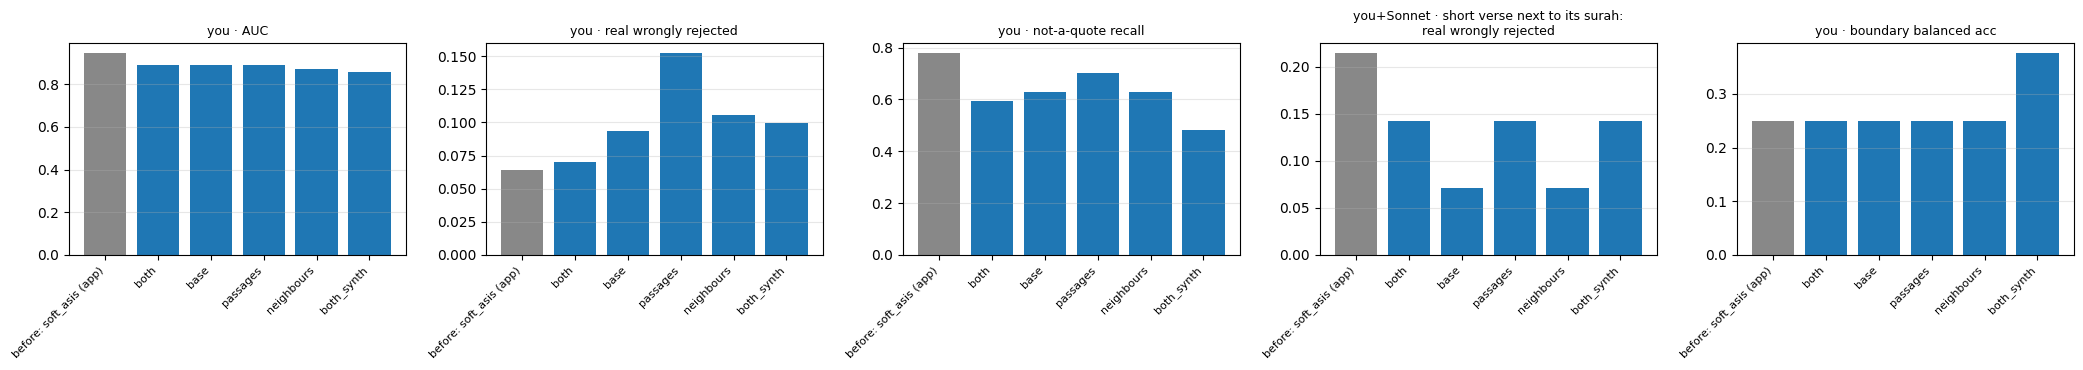

In [10]:
import matplotlib.pyplot as plt

def val(m, group, part, key, sub=None):
    x = ((m["groups"].get(group) or {}).get(part) or {})
    x = x.get(sub, {}) if sub else x
    x = x.get(key)
    return x[0] if isinstance(x, list) else x

def slice_rej(m, group, name):
    for sl in (m["groups"].get(group) or {}).get("verdict", {}).get("by context", []):
        if sl["slice"] == name:
            return sl["real quotes wrongly rejected"][0]

panels = [("you · AUC", lambda m: val(m, "you", "verdict", "AUC P(not a quote)")),
          ("you · real wrongly rejected", lambda m: val(m, "you", "verdict", "real quotes wrongly rejected")),
          ("you · not-a-quote recall", lambda m: val(m, "you", "verdict", "not-a-quote recall")),
          ("you+Sonnet · short verse next to its surah:\nreal wrongly rejected",
           lambda m: slice_rej(m, "you + Sonnet", "short (1-3 words) with a same-surah verse around")),
          ("you · boundary balanced acc", lambda m: val(m, "you", "boundary", "balanced accuracy"))]
names = [m["name"] for m in models]
fig, ax = plt.subplots(1, len(panels), figsize=(4.2 * len(panels), 3.8))
for a, (title, f) in zip(ax, panels):
    ys = [f(m) for m in models]
    a.bar(range(len(models)), [y if y is not None else 0 for y in ys], color=["#888"] + ["C0"] * (len(models) - 1))
    a.set_xticks(range(len(models)), names, rotation=45, ha="right", fontsize=8); a.set_title(title, fontsize=9); a.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(WORK / "results" / "ablation.png", dpi=120); plt.show()

## 11. (Optional) Push the models to the Hugging Face Hub — private
Every run that trained. In the app, choose the repo as the Laya checkpoint: its config tells the app to send envelope v2
with that run's options.

In [11]:
if PUSH_TO_HUB and HF_TOKEN:
    from huggingface_hub import HfApi
    api = HfApi(token=HF_TOKEN)
    for n in RUNS:
        out = WORK / "models" / n
        if not (out / "model.safetensors").exists():
            continue
        repo = f"{HUB_PREFIX}-{n}"
        api.create_repo(repo, repo_type="model", private=True, exist_ok=True)
        api.upload_folder(folder_path=str(out), repo_id=repo, repo_type="model",
                          commit_message=f"laya-multilingual fine-tuned on Wahy laya_v2 ({n}, envelope v2, 2 epochs)")
        print("pushed", repo)

pushed ZenoAbderrahim/laya-wahy-v2-both
pushed ZenoAbderrahim/laya-wahy-v2-base
pushed ZenoAbderrahim/laya-wahy-v2-passages
pushed ZenoAbderrahim/laya-wahy-v2-neighbours
pushed ZenoAbderrahim/laya-wahy-v2-both_synth
